In [19]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import yfinance as yf
from scipy.stats import norm
from scipy.stats import gmean

In [20]:
tickers = ["AAPL", "MSFT", "NVDA"]
data = yf.download(tickers, period="3y", progress=False)["Close"].dropna()

# Retornos logarítmicos 
log_returns = np.log(data / data.shift(1)).dropna()

# Matriz de correlación
corr_matrix = log_returns.corr()
cov_matrix = log_returns.cov()
print(corr_matrix.round(4).to_string())

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3411  0.2744
MSFT    0.3411  1.0000  0.4098
NVDA    0.2744  0.4098  1.0000


Esta parte descarga los precios históricos de los últimos 3 años para Apple, Microsoft y Nvidia. Luego, calcula los rendimientos diarios de cada acción y crea una tabla (matriz de correlación) para ver qué tanto se mueven juntas o por su cuenta en el mercado.

In [21]:
escenarios = {
    "A": np.array([1, 0, 0]),
    "B": np.array([0.33, 0.33, 0.33]),
    "C": np.array([0.2, 0.2, 0.6]),
}

V0_total = 100000

mu_diario = log_returns.mean().values
sigma_diario = log_returns.std().values

# Drift y Volatilidad anualizados 
mu = mu_diario * 252 + 0.5 * (sigma_diario ** 2) * 252
sigma = sigma_diario * np.sqrt(252)

En esta parte se muestran los escenarios a calcular $$A[1,0,0], B[0.33,0.33,0.33], C[0.2,0.2,0.6]$$ Luego calculo el drift y la volatilidad anualizada

In [22]:
M = 10000
T = 1

L = np.linalg.cholesky(cov_matrix)
num_activos = len(cov_matrix)
E = np.random.normal(0, 1, [num_activos, M])
Z = np.tensordot(L, E, axes=1)
S0 = np.array(data.iloc[-1])

En esta parte se define el número de simulaciones (10,000) y el tiempo (1 año). Después, se aplica la descomposición de Cholesky a la matriz de covarianza para generar números aleatorios que simulan el comportamiento real del mercado y calcula los precios futuros estimados para cada acción a partir de su último precio registrado (S0)


In [23]:
mu_col = np.reshape(mu, (-1, 1))
sigma_col = np.reshape(sigma, (-1, 1))
S0_col = np.reshape(S0, (-1, 1))

# Matriz de precios finales por activo individual
ST_matriz = S0_col * np.exp((mu_col - 0.5 * (sigma_col ** 2)) * T + sigma_col * np.sqrt(T) * Z)

# Diccionario para guardar los resultados
resultados_netos = {}

En esta parte se reorganizan los parámetros en columnas para aplicar la fórmula matemática de proyección de precios para cada acción en todas las simulaciones. Al final se crea un diccionario vacío para guardar los resultados de los portafolios.

In [24]:
for nombre, pesos in escenarios.items():
    ST_portafolio = 0
    for j, peso in enumerate(pesos):
        # Rentabilidad del activo (Precio Final / Precio Inicial)
        rentabilidad_activo = ST_matriz[j, :] / S0[j]
        # Valor final escalado
        ST_portafolio = ST_portafolio + (peso * rentabilidad_activo * V0_total)
        
    # Ganancia o pérdida neta 
    ganancia_neta = ST_portafolio - V0_total
    resultados_netos[nombre] = ganancia_neta

En este bloque recorre cada escenario de inversión para calcular el valor final del portafolio en todas las simulaciones, multiplicando el peso de cada activo por su rentabilidad esperada y el capital inicial. Al final le resta los $100,000 iniciales para obtener la ganancia o pérdida neta de cada estrategia.

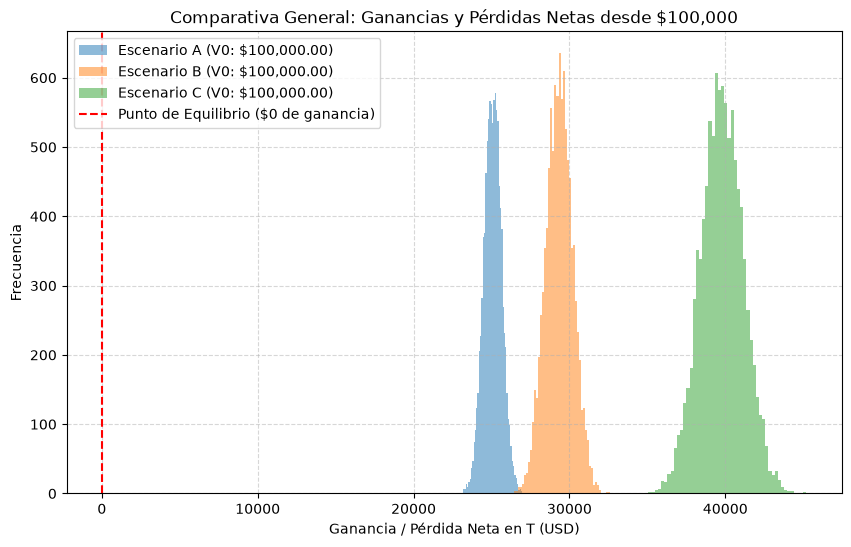

In [25]:
plt.figure(figsize=(10, 6))

for nombre, ganancia_neta in resultados_netos.items():
    plt.hist(
        ganancia_neta,
        bins=50,
        alpha=0.5,
        label=f"Escenario {nombre} (V0: ${V0_total:,.2f})"
    )

plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Punto de Equilibrio ($0 de ganancia)')
plt.title("Comparativa General: Ganancias y Pérdidas Netas desde $100,000")
plt.xlabel("Ganancia / Pérdida Neta en T (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

En esta parte se genera un histograma que muestra y compara las ganancias y pérdidas netas de los tres escenarios. 

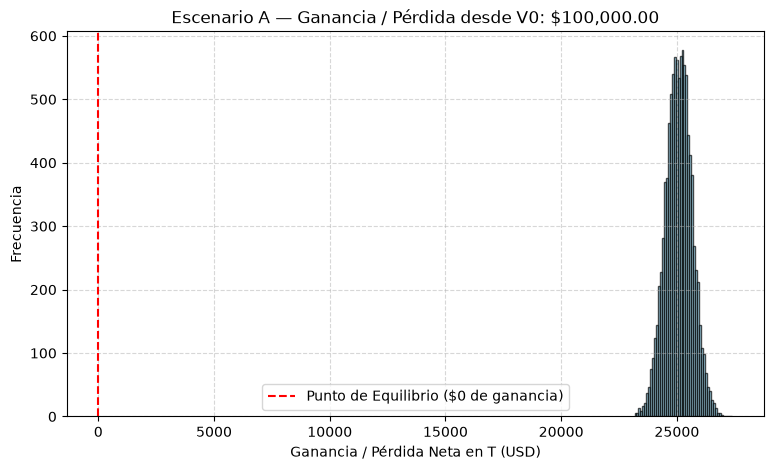

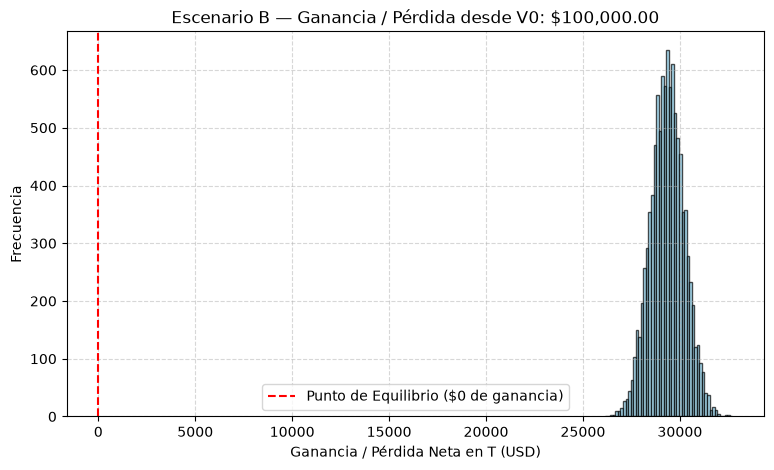

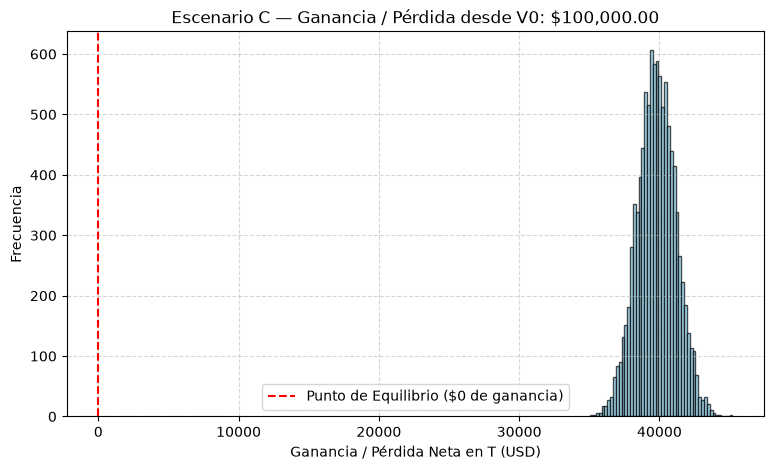

In [26]:
for nombre, ganancia_neta in resultados_netos.items():
    plt.figure(figsize=(9, 5))
    
    plt.hist(
        ganancia_neta,
        bins=50,
        alpha=0.7,
        color='skyblue',
        edgecolor='black'
    )
    
    plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Punto de Equilibrio ($0 de ganancia)')
    plt.title(f"Escenario {nombre} — Ganancia / Pérdida desde V0: ${V0_total:,.2f}")
    plt.xlabel("Ganancia / Pérdida Neta en T (USD)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

# VaR y CVaR


In [27]:
confianza = 0.95
alpha = 1 - confianza  # 0.05 (5%)

for nombre, ganancia_neta in resultados_netos.items():
    # VaR histórico basado en la ganancia/pérdida neta (percentil 5)
    var_val = np.percentile(ganancia_neta, alpha * 100)
    # CVaR (Expected Shortfall): promedio de las pérdidas peores o iguales al VaR
    cvar_val = ganancia_neta[ganancia_neta <= var_val].mean()
    
    print(f"Escenario {nombre}: VaR 95% = ${-var_val:,.2f} USD (Pérdida) | CVaR 95% = ${-cvar_val:,.2f} USD")

Escenario A: VaR 95% = $-24,133.69 USD (Pérdida) | CVaR 95% = $-23,894.83 USD
Escenario B: VaR 95% = $-27,898.38 USD (Pérdida) | CVaR 95% = $-27,556.28 USD
Escenario C: VaR 95% = $-37,530.60 USD (Pérdida) | CVaR 95% = $-36,970.62 USD


Esta parte calcula el riesgo de cada escenario con un nivel de confianza del 95% (un margen del 5% para pérdidas extremas). Para cada portafolio, se calcula el VaR (la pérdida máxima esperada en ese 5% de casos malos) y el CVaR (el promedio de lo que se perdería si las cosas empeoran aún más).

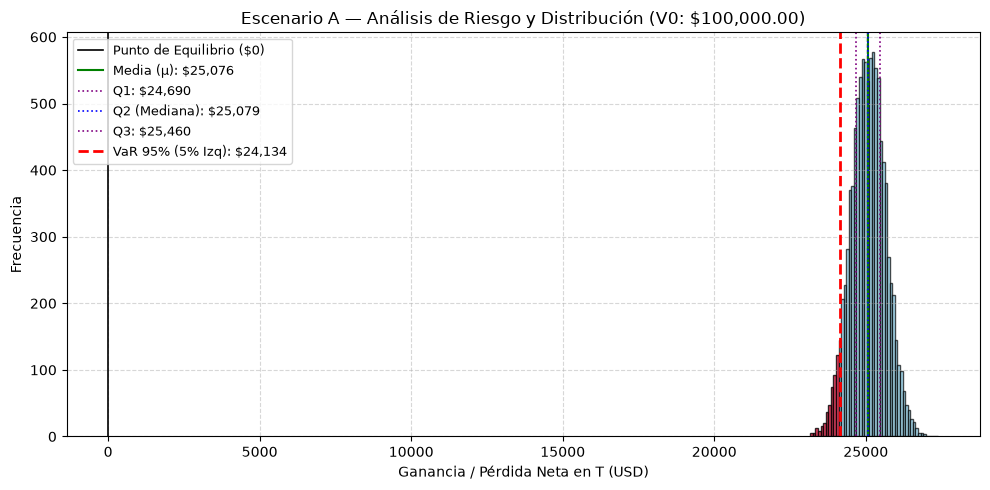

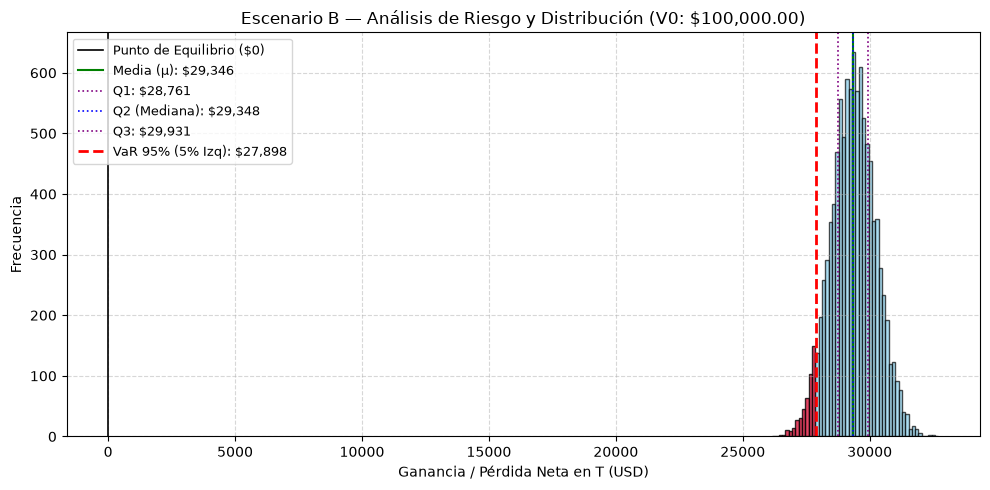

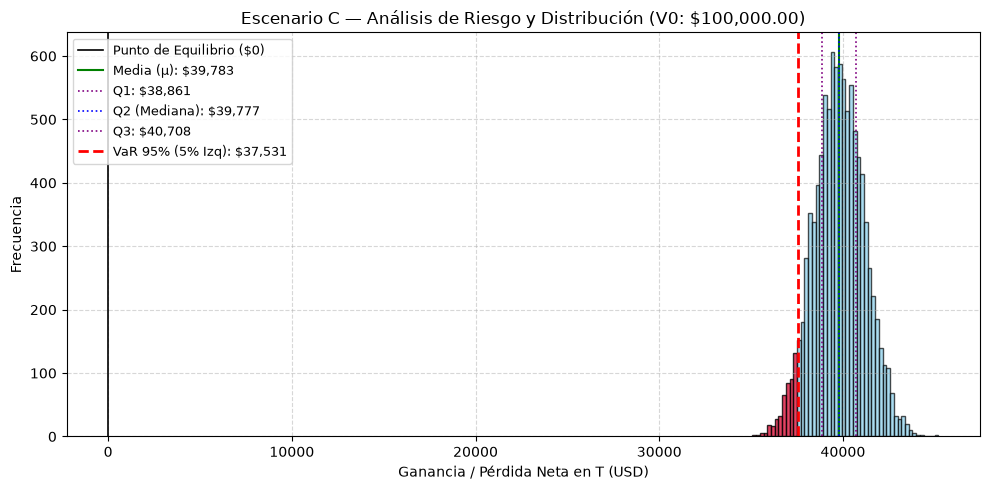

In [28]:
for nombre, ganancia_neta in resultados_netos.items():
    plt.figure(figsize=(10, 5))
    
    # Histograma base
    n, bins, patches = plt.hist(
        ganancia_neta,
        bins=50,
        alpha=0.7,
        color='skyblue',
        edgecolor='black'
    )
    
    # Estadísticos
    q1 = np.percentile(ganancia_neta, 25)
    q2 = np.percentile(ganancia_neta, 50)  # Mediana
    q3 = np.percentile(ganancia_neta, 75)
    media = np.mean(ganancia_neta)
    var_95 = np.percentile(ganancia_neta, 5) # Percentil 5 (5% de la cola izquierda)
    
    # Resaltar la cola del 5% (izquierda del VaR)
    for i in range(len(bins) - 1):
        if bins[i+1] <= var_95:
            patches[i].set_facecolor('crimson')
            patches[i].set_alpha(0.8)

    # Líneas de referencia
    plt.axvline(0, color='black', linestyle='-', linewidth=1.2, label='Punto de Equilibrio ($0)')
    plt.axvline(media, color='green', linestyle='-', linewidth=1.5, label=f'Media (μ): ${media:,.0f}')
    plt.axvline(q1, color='purple', linestyle=':', linewidth=1.2, label=f'Q1: ${q1:,.0f}')
    plt.axvline(q2, color='blue', linestyle=':', linewidth=1.2, label=f'Q2 (Mediana): ${q2:,.0f}')
    plt.axvline(q3, color='purple', linestyle=':', linewidth=1.2, label=f'Q3: ${q3:,.0f}')
    plt.axvline(var_95, color='red', linestyle='--', linewidth=2, label=f'VaR 95% (5% Izq): ${var_95:,.0f}')
    
    plt.title(f"Escenario {nombre} — Análisis de Riesgo y Distribución (V0: ${V0_total:,.2f})")
    plt.xlabel("Ganancia / Pérdida Neta en T (USD)")
    plt.ylabel("Frecuencia")
    plt.legend(loc='upper left', fontsize=9)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

Esta parte crea una gráfica detallada para cada escenario de inversión. Calcula los cuartiles ($Q_1, Q_2, Q_3$), la media y el VaR al 95%, y pinta de color rojo la barra correspondiente a la cola izquierda para mostrar el 5% de las peores pérdidas.